In [7]:
import jax
import jax.numpy as jnp

from hcnn.environment import Environment
from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.system.system_linear import SystemLinear

state_matrix = jnp.array([[0, 3], [0, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemLinear(state_matrix, input_matrix)
policy = PolicyLQR.factory(system, state_cost, input_cost)
environment = Environment(system, policy)

In [8]:
view_range = 2.0
samples_per_axis = 41
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
next_states = jax.vmap(environment.step, in_axes=(0))(states)
difference = next_states - states
unit_difference = difference / jnp.linalg.norm(difference, axis=-1, keepdims=True)

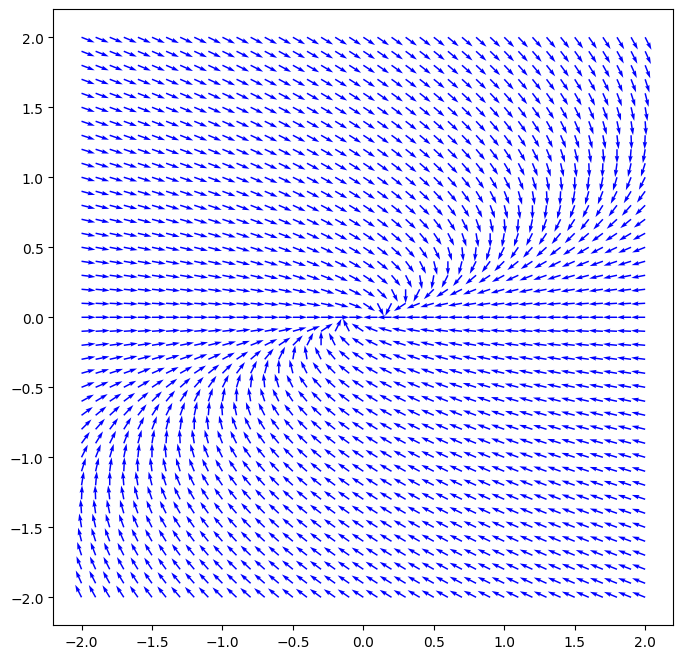

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.quiver(
    states[:, 0],
    states[:, 1],
    unit_difference[:, 0],
    unit_difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=10,
    color="blue",
)
plt.show()